# FAIRyMAGs Pipeline Benchmark

This notebook compares MAGs recovery across different pipelines:
- **FAIRyMAGs (v0.4, v0.5)**: [MAGs-building workflow](https://iwc.galaxyproject.org/workflow/mags-building-main/)
- **MGnify Genomes Generation pipeline**: https://github.com/EBI-Metagenomics/genomes-generation
- **MAGNETO (v1, v2)**: 10.1128/msystems.00432-22
- **nf-core/mag (v1, v2)**: 10.1093/nargab/lqac007
- **Metagenomics-Toolkit (metaspades, metaspades v2, megahit, megahit multisample)**: https://doi.org/10.1093/nargab/lqaf093

## Workflow links
- dRep benchmarking: https://usegalaxy.eu/u/paulzierep/w/drep-fairymags-benchmark
- Example history: https://usegalaxy.eu/u/paulzierep/h/drep-fairymags-benchmark-1

## Data
Input data is stored in `../data/benchmark/`:
- `cdb_clusters_95.tsv`: dRep clustering output (secondary clusters at 95% ANI)
- `checkm2.tsv`: CheckM2 quality assessment results

Plots and metrics are written to `../results/benchmark/`.

Current data: [CheckM2-filtered benchmark history](https://usegalaxy.eu/histories/view?id=11ac94870d0bb33ae650040e474d86c8). The 95% ANI plots use all 1,903 genomes passing completeness ≥75% and contamination ≤25%. Source labels follow the workflow identifier suffixes; the four Metagenome tk runs remain separate.


In [1]:
#!/usr/bin/env python3

import pandas as pd
import sys
from pathlib import Path

# === CONFIGURATION ===
DATA_DIR = Path("../data/benchmark")
RESULTS_DIR = Path("../results/benchmark")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Data directory: {DATA_DIR.resolve()}")
print(f"Results directory: {RESULTS_DIR.resolve()}")

Data directory: /home/paul-zierep/git/usegalaxy-eu/FAIRyMAGs/data/benchmark
Results directory: /home/paul-zierep/git/usegalaxy-eu/FAIRyMAGs/results/benchmark


In [2]:
###################
# Load datasets from local files
###################

cdb_95 = pd.read_csv(DATA_DIR / "cdb_clusters_95.tsv")
checkm2 = pd.read_csv(DATA_DIR / "checkm2.tsv", sep="\t", comment="#")

print(f"Loaded cdb_clusters_95 with shape {cdb_95.shape}")
print(f"Loaded checkm2 with shape {checkm2.shape}")

###################
# Preview
###################

print("\n--- CDB preview ---")
print(cdb_95.head())

print("\n--- CheckM2 preview ---")
print(checkm2.head())


Loaded cdb_clusters_95 with shape (1903, 6)
Loaded checkm2 with shape (3629, 14)

--- CDB preview ---
                          genome secondary_cluster  threshold cluster_method  \
0   1041930.PRJNA73221_ref.fasta               1_0       0.05        average   
1  1120985.PRJNA188816_ref.fasta               2_0       0.05        average   
2  1217712.PRJNA183309_ref.fasta               3_0       0.05        average   
3   520709.PRJNA183323_ref.fasta               4_0       0.05        average   
4  1217715.PRJNA183332_ref.fasta               5_0       0.05        average   

  comparison_algorithm  primary_cluster  
0                ANImf                1  
1                ANImf                2  
2                ANImf                3  
3                ANImf                4  
4                ANImf                5  

--- CheckM2 preview ---
                      Name  Completeness  Contamination  \
0  1121288.PRJNA188854_ref         99.98           0.16   
1  1200352.PRJNA168617

In [3]:
MIN_COMPLETENESS = 75
MAX_CONTAMINATION = 25

hq_genomes = checkm2.loc[
    (checkm2["Completeness"] >= MIN_COMPLETENESS) &
    (checkm2["Contamination"] <= MAX_CONTAMINATION),
    "Name"
].unique()

print(f"High-quality genomes: {len(hq_genomes)}")

High-quality genomes: 1903


In [4]:
cdb_95["genome"] = cdb_95["genome"].str.replace(r"\.fasta$", "", regex=True)
cdb_95

,genome,secondary_cluster,threshold,cluster_method,comparison_algorithm,primary_cluster
0,1041930.PRJNA73221_ref,1_0,0.05,average,ANImf,1
1,1120985.PRJNA188816_ref,2_0,0.05,average,ANImf,2
2,1217712.PRJNA183309_ref,3_0,0.05,average,ANImf,3
3,520709.PRJNA183323_ref,4_0,0.05,average,ANImf,4
4,1217715.PRJNA183332_ref,5_0,0.05,average,ANImf,5
...,...,...,...,...,...,...
1898,1124780.PRJNA182711_ref,341_0,0.05,average,ANImf,341
1899,1173027.PRJNA158839_ref,342_0,0.05,average,ANImf,342
1900,1353246.PRJNA210247_ref,343_0,0.05,average,ANImf,343
1901,1365176.PRJNA212068_ref,344_0,0.05,average,ANImf,344


In [5]:
cdb_filtered_95 = cdb_95[cdb_95["genome"].isin(hq_genomes)].copy()

print(f"Filtered CDB shape: {cdb_filtered_95.shape}")
print(cdb_filtered_95.head())

Filtered CDB shape: (1903, 6)
                    genome secondary_cluster  threshold cluster_method  \
0   1041930.PRJNA73221_ref               1_0       0.05        average   
1  1120985.PRJNA188816_ref               2_0       0.05        average   
2  1217712.PRJNA183309_ref               3_0       0.05        average   
3   520709.PRJNA183323_ref               4_0       0.05        average   
4  1217715.PRJNA183332_ref               5_0       0.05        average   

  comparison_algorithm  primary_cluster  
0                ANImf                1  
1                ANImf                2  
2                ANImf                3  
3                ANImf                4  
4                ANImf                5  


In [6]:
cdb_filtered_95['genome']

0        1041930.PRJNA73221_ref
1       1120985.PRJNA188816_ref
2       1217712.PRJNA183309_ref
3        520709.PRJNA183323_ref
4       1217715.PRJNA183332_ref
                 ...           
1898    1124780.PRJNA182711_ref
1899    1173027.PRJNA158839_ref
1900    1353246.PRJNA210247_ref
1901    1365176.PRJNA212068_ref
1902      694427.PRJNA42009_ref
Name: genome, Length: 1903, dtype: str


Genomes per source:
source
True Genomes                     437
nf-core (v2)                     322
Metagenome tk (metaspades v2)    200
Metagenome tk (metaspades)       157
Metagenome tk (megahit) MSB      152
MAGNETO (v2) MSB                 150
Metagenome tk (megahit)          131
MAGNETO (v1)                     130
nf-core (v1)                     123
MGnify                            36
FAIRyMAGs (v0.5)                  35
FAIRyMAGs (v0.4)                  30
Name: count, dtype: int64

Species-level representative MAGs:
source
FAIRyMAGs (v0.4)                  30
FAIRyMAGs (v0.5)                  35
MAGNETO (v1)                      21
MAGNETO (v2) MSB                  23
MGnify                            36
Metagenome tk (megahit)           17
Metagenome tk (megahit) MSB       22
Metagenome tk (metaspades v2)     33
Metagenome tk (metaspades)        23
True Genomes                     385
nf-core (v1)                      26
nf-core (v2)                      28
dtype: int64


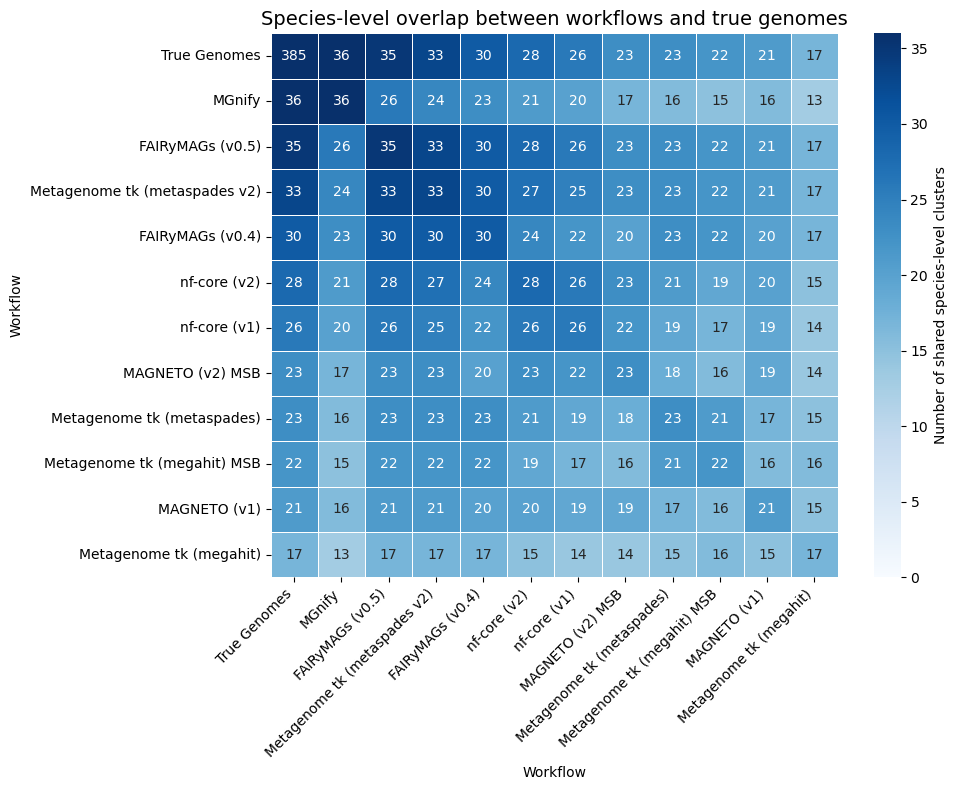

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Exact identifier suffixes from the benchmark workflow's relabeling steps.
# Do not infer the pipeline from a binner name (e.g. SemiBin2).
SOURCE_SUFFIXES = {
    '_metagenome_tk_metaspades_v2': 'Metagenome tk (metaspades v2)',
    '_metagenome_tk_megahit_multisample': 'Metagenome tk (megahit) MSB',
    '_metagenome_tk_metaspades': 'Metagenome tk (metaspades)',
    '_metagenome_tk_megahit': 'Metagenome tk (megahit)',
    '_nfcore_v1': 'nf-core (v1)',
    '_nfcore_v2': 'nf-core (v2)',
    '_fairymags04': 'FAIRyMAGs (v0.4)',
    '_fairymags05': 'FAIRyMAGs (v0.5)',
    '_magneto_megahit': 'MAGNETO (v1)',
    '_magneto_metaspades': 'MAGNETO (v2) MSB',
    '_mgnify': 'MGnify',
    '_ref': 'True Genomes',
}

def get_source(name):
    matches = [label for suffix, label in SOURCE_SUFFIXES.items()
               if name.endswith(suffix)]
    if len(matches) != 1:
        raise ValueError(f'Expected one workflow suffix for {name!r}, got {matches}')
    return matches[0]

# Validate all quality-report identifiers, not just those passing QC.
checkm2['Name'].map(get_source)
df = cdb_filtered_95.copy()
df['source'] = df['genome'].map(get_source)
assert len(df) == len(cdb_95), 'QC-filtered dRep inputs must all match CheckM2'
assert df['source'].nunique() == 12, 'Expected 11 workflows plus reference genomes'
assert df.loc[df['source'].str.startswith('Metagenome tk'), 'source'].nunique() == 4
print('\nGenomes per source:')
print(df['source'].value_counts())

# Count genomes per cluster per source
per_cluster = (
    df.groupby(['secondary_cluster', 'source'])
      .size()
      .unstack(fill_value=0)
)

# Convert to presence/absence
presence = per_cluster > 0

# Print dereplicated genome counts
print("\nSpecies-level representative MAGs:")
print(presence.sum())

# Create overlap matrix
sources = presence.columns
overlap_matrix = pd.DataFrame(0, index=sources, columns=sources)

# Count shared clusters
for i in sources:
    for j in sources:
        overlap_matrix.loc[i, j] = (
            (presence[i]) & (presence[j])
        ).sum()

# Sort by overlap with True Genomes
if 'True Genomes' in overlap_matrix.columns:
    sorted_sources = (
        overlap_matrix['True Genomes']
        .sort_values(ascending=False)
        .index
    )

    overlap_matrix = overlap_matrix.loc[
        sorted_sources,
        sorted_sources
    ]

# Optional: mask upper triangle
mask = np.triu(
    np.ones_like(overlap_matrix, dtype=bool),
    k=1
)

# Set heatmap color scale max excluding True Genomes
workflow_only = overlap_matrix.drop(
    index='True Genomes',
    columns='True Genomes',
    errors='ignore'
)

vmax = workflow_only.to_numpy().max()

# Plot heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    overlap_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    vmin=0,
    vmax=vmax,
    # mask=mask,
    linewidths=0.5,
    cbar_kws={'label': 'Number of shared species-level clusters'}
)

plt.title(
    'Species-level overlap between workflows and true genomes',
    fontsize=14
)

plt.xlabel('Workflow')
plt.ylabel('Workflow')

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()

# Save
plt.savefig(
    RESULTS_DIR / "heatmap_mags_benchmark.svg",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    RESULTS_DIR / "heatmap_mags_benchmark.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


/tmp/ipykernel_3344548/762709517.py:213: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


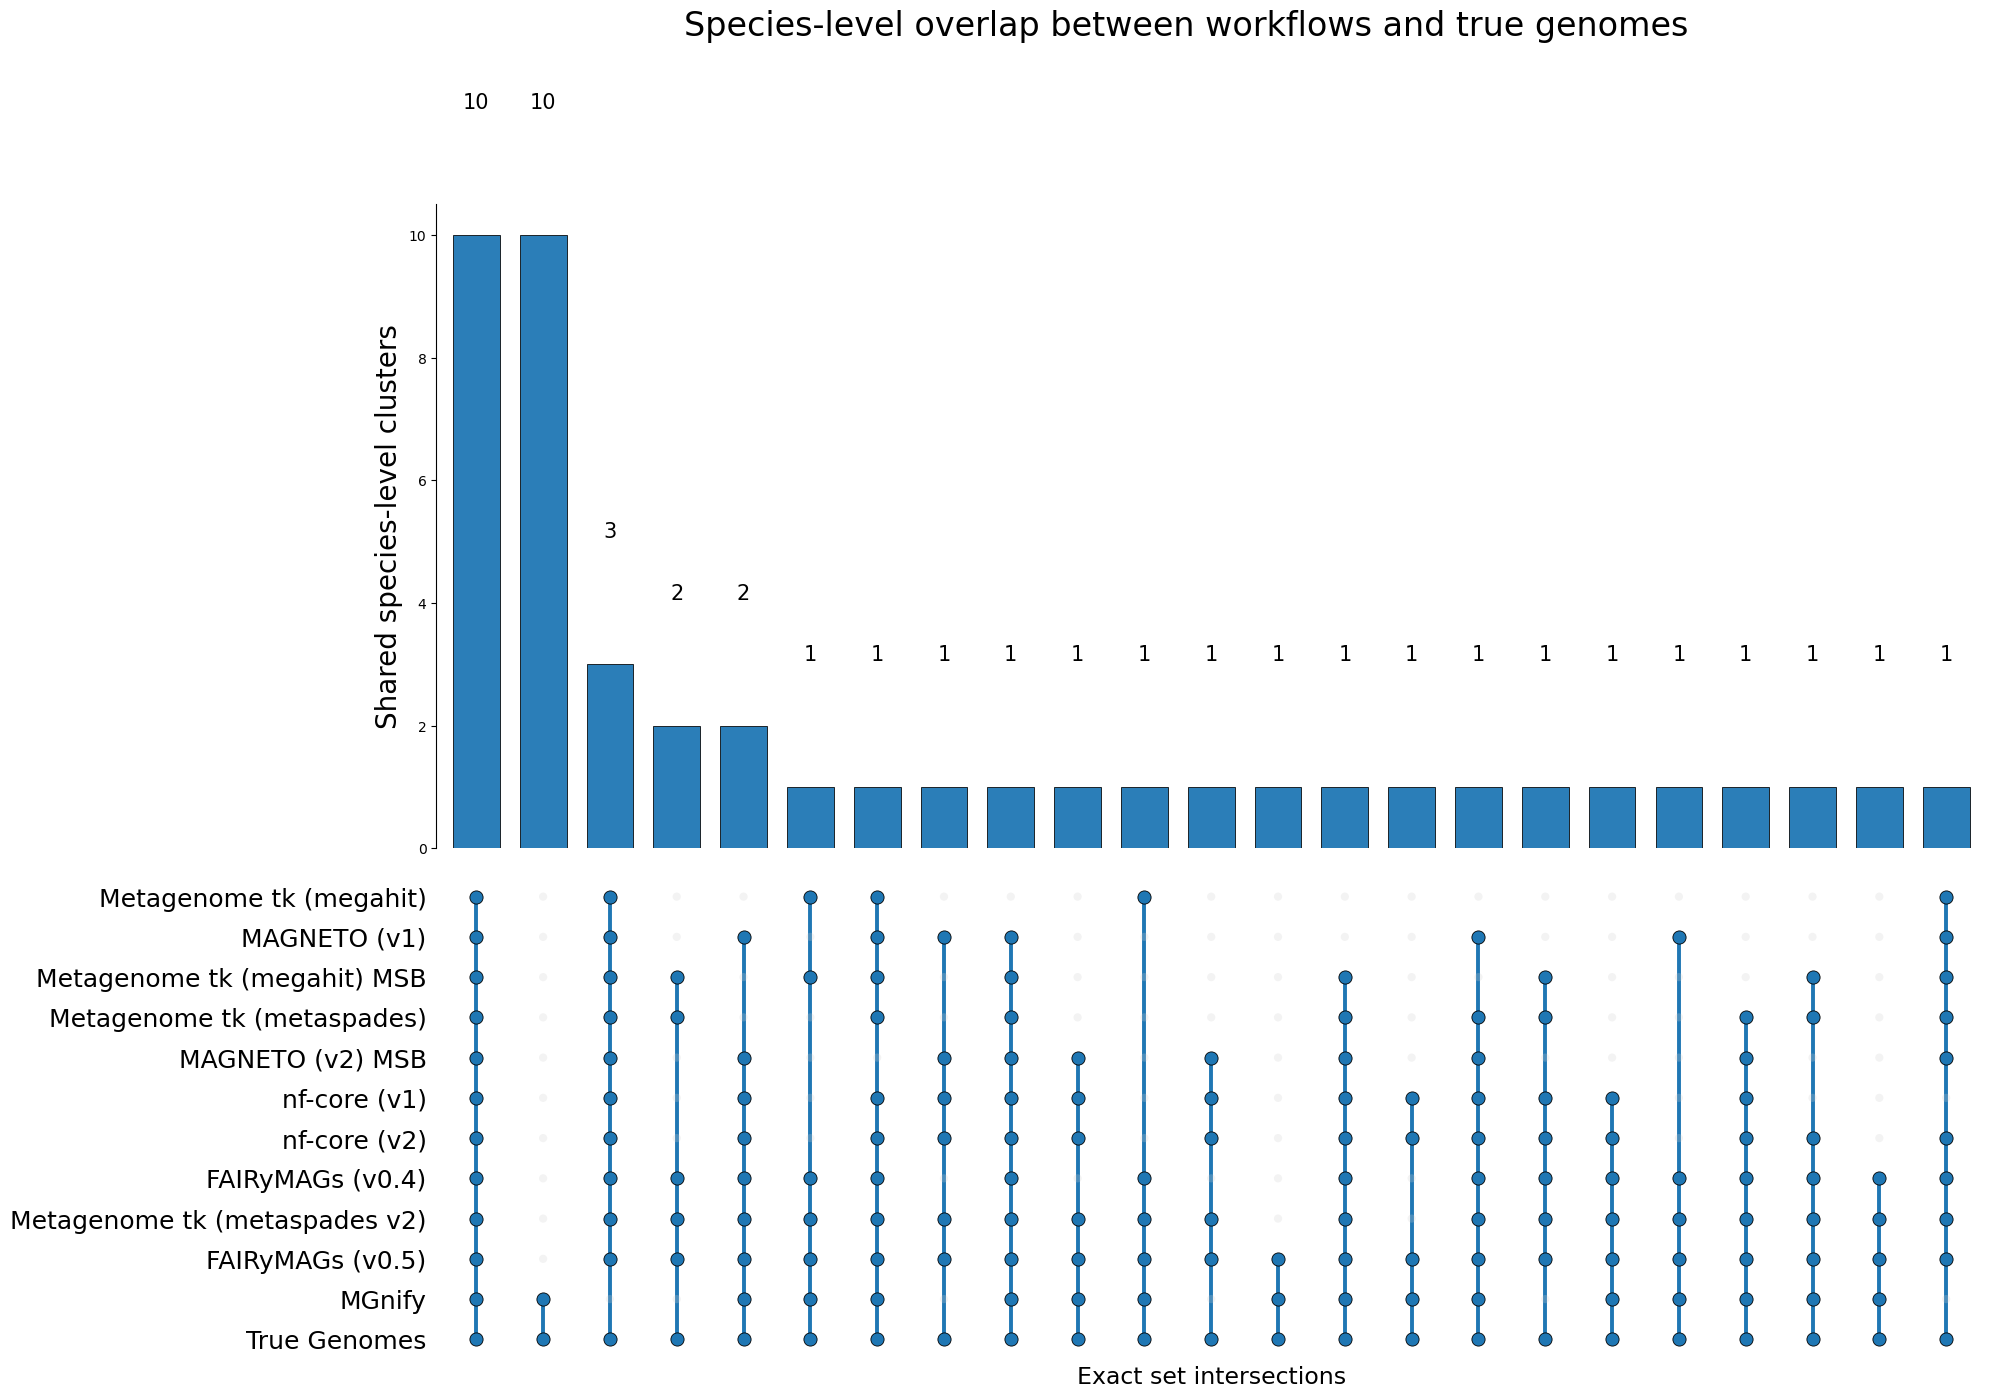

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

df['source'] = df['genome'].apply(get_source)
#df = df[df['source'] != 'MAGNETO (v2)']

per_cluster = (
    df.groupby(['secondary_cluster', 'source'])
      .size()
      .unstack(fill_value=0)
)

presence = per_cluster > 0
sources = list(presence.columns)

# ------------------------
# Sort by overlap with True Genomes
# ------------------------

if 'True Genomes' in sources:

    overlap_with_ref = {
        s: (presence[s] & presence['True Genomes']).sum()
        for s in sources
    }

    sources = sorted(
        sources,
        key=lambda s: overlap_with_ref[s],
        reverse=True
    )

    presence = presence[sources]

# ------------------------
# TRUE UpSet signatures
# ------------------------

signatures = presence.astype(int).apply(tuple, axis=1)
signature_counts = signatures.value_counts()

# ------------------------
# KEEP ALL intersections
# BUT REMOVE:
# True Genomes-only singleton
# ------------------------

intersections = []

for sig, count in signature_counts.items():

    if count == 0:
        continue

    # Remove only:
    # (True Genomes = 1) AND all others = 0
    if 'True Genomes' in sources:

        ref_idx = sources.index('True Genomes')

        if (
            sig[ref_idx] == 1
            and sum(sig) == 1
        ):
            continue

    intersections.append({
        'sets': sig,
        'size': count
    })

# Sort descending
intersections.sort(key=lambda x: -x['size'])

# ------------------------
# SHOW ALL intersections
# ------------------------

top = intersections

# ------------------------
# Plot
# ------------------------

fig = plt.figure(figsize=(20, 15))

gs = GridSpec(
    2,
    1,
    figure=fig,
    height_ratios=[2, 1.5],
    hspace=0.05
)

ax_bar = fig.add_subplot(gs[0])
ax_dot = fig.add_subplot(gs[1])

n_cols = len(top)

COLOR = '#1f77b4'

# ------------------------
# BAR PLOT
# ------------------------

for i, inter in enumerate(top):

    ax_bar.bar(
        i,
        inter['size'],
        color=COLOR,
        alpha=0.95,
        width=0.7,
        edgecolor='black',
        linewidth=0.6
    )

    ax_bar.text(
        i,
        inter['size'] + 2,
        str(inter['size']),
        ha='center',
        va='bottom',
        fontsize=15
    )

ax_bar.set_xlim(-0.6, n_cols - 0.4)

ax_bar.set_xticks([])

ax_bar.set_ylabel(
    'Shared species-level clusters',
    fontsize=20
)

ax_bar.spines[['top', 'right', 'bottom']].set_visible(False)

# ------------------------
# DOT MATRIX
# ------------------------

ax_dot.set_xlim(-0.6, n_cols - 0.4)

ax_dot.set_ylim(
    -0.5,
    len(sources) - 0.5
)

ax_dot.set_xticks([])

ax_dot.set_yticks(range(len(sources)))

ax_dot.set_yticklabels(
    sources,
    fontsize=18
)

ax_dot.spines[
    ['top', 'right', 'bottom', 'left']
].set_visible(False)

ax_dot.tick_params(left=False)

for i, inter in enumerate(top):

    sig = inter['sets']

    active_rows = [
        idx for idx, v in enumerate(sig)
        if v == 1
    ]

    # Connection line
    if len(active_rows) > 1:

        ax_dot.plot(
            [i, i],
            [min(active_rows), max(active_rows)],
            color=COLOR,
            lw=2.8,
            zorder=1
        )

    # Dots
    for ri in range(len(sources)):

        active = sig[ri] == 1

        ax_dot.scatter(
            i,
            ri,
            s=90 if active else 35,
            color=COLOR if active else '#d0d0d0',
            alpha=1.0 if active else 0.25,
            edgecolor='black' if active else 'none',
            linewidth=0.6,
            zorder=2
        )

ax_dot.set_xlabel(
    'Exact set intersections',
    fontsize=17
)

plt.suptitle(
    'Species-level overlap between workflows and true genomes',
    fontsize=24,
    y=1.01
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "upset_mags_benchmark.svg",
    dpi=300,
    bbox_inches='tight'
)

plt.savefig(
    RESULTS_DIR / "upset_mags_benchmark.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

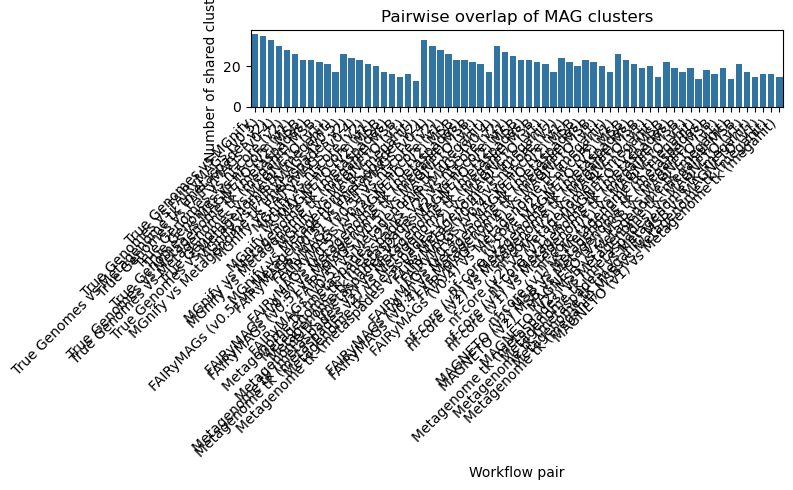

In [9]:
import pandas as pd
import itertools
import matplotlib.pyplot as plt
import seaborn as sns

pairs = []

sources = overlap_matrix.columns

for i, j in itertools.combinations(sources, 2):
    pairs.append({
        "pair": f"{i} vs {j}",
        "overlap": overlap_matrix.loc[i, j]
    })

pairs_df = pd.DataFrame(pairs)

# Plot
plt.figure(figsize=(8,5))
sns.barplot(data=pairs_df, x="pair", y="overlap")

plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of shared clusters")
plt.xlabel("Workflow pair")
plt.title("Pairwise overlap of MAG clusters")
plt.tight_layout()
plt.show()

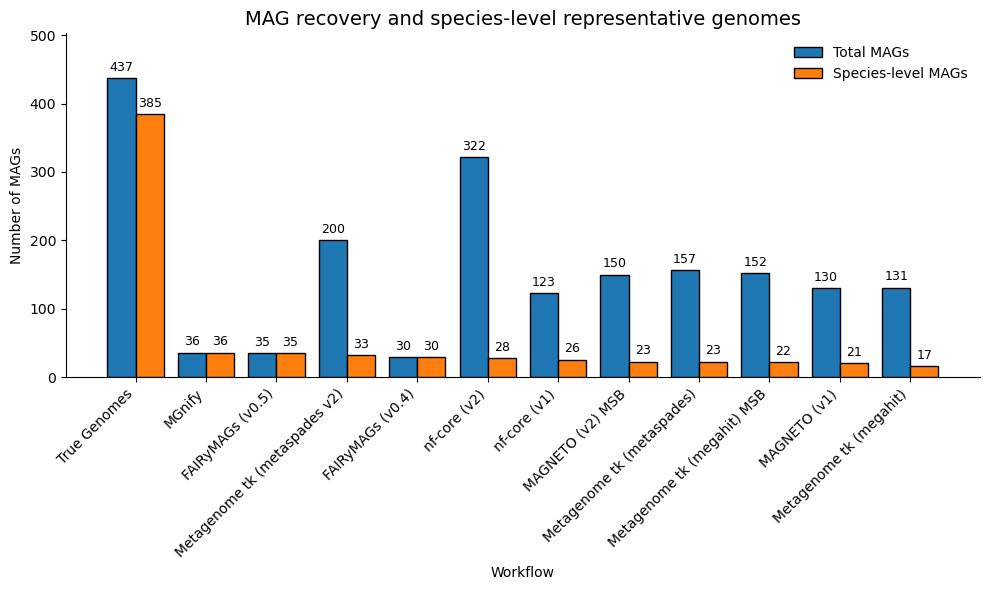

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --- Prepare data ---
counts = df['source'].value_counts()
cluster_counts = presence.sum()

# Sort by species-level MAG recovery
order = cluster_counts.sort_values(ascending=False).index

# Reorder both series
counts = counts.reindex(order)
cluster_counts = cluster_counts.reindex(order)

# --- Set positions ---
x = np.arange(len(order))
width = 0.4

# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width/2,
    counts,
    width,
    label="Total MAGs",
    edgecolor='black'
)

bars2 = ax.bar(
    x + width/2,
    cluster_counts,
    width,
    label="Species-level MAGs",
    edgecolor='black'
)

# --- Add value labels ---
ax.bar_label(bars1, padding=3, fontsize=9)
ax.bar_label(bars2, padding=3, fontsize=9)

# --- Prevent clipping ---
max_val = max(counts.max(), cluster_counts.max())
ax.set_ylim(0, max_val * 1.15)

# --- Labels & styling ---
ax.set_xticks(x)
ax.set_xticklabels(order, rotation=45, ha='right')

ax.set_ylabel("Number of MAGs")
ax.set_xlabel("Workflow")

ax.set_title(
    "MAG recovery and species-level representative genomes",
    fontsize=14
)

ax.legend(frameon=False)

# Cleaner look
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

# --- Save ---
plt.savefig(
    RESULTS_DIR / "mags_grouped_bar_with_values.svg",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    RESULTS_DIR / "mags_grouped_bar_with_values.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [11]:
# Identify clusters that contain at least one true genome
ref_clusters = presence[presence['True Genomes']].index

results = []

for source in presence.columns.drop('True Genomes'):
    # Clusters where this workflow has MAGs
    pred_clusters = presence[presence[source]].index
    
    # True Positives: predicted clusters that match reference clusters
    tp = len(set(pred_clusters) & set(ref_clusters))
    
    # False Positives: predicted clusters without reference
    fp = len(set(pred_clusters) - set(ref_clusters))
    
    # False Negatives: reference clusters not recovered
    fn = len(set(ref_clusters) - set(pred_clusters))
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    results.append({
        "source": source,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision": precision,
        "recall": recall
    })

metrics_df = pd.DataFrame(results)

print("\n=== Precision / Recall per workflow ===")
print(metrics_df)



=== Precision / Recall per workflow ===
                           source  TP  FP   FN  precision    recall
0                          MGnify  36   0  349        1.0  0.093506
1                FAIRyMAGs (v0.5)  35   0  350        1.0  0.090909
2   Metagenome tk (metaspades v2)  33   0  352        1.0  0.085714
3                FAIRyMAGs (v0.4)  30   0  355        1.0  0.077922
4                    nf-core (v2)  28   0  357        1.0  0.072727
5                    nf-core (v1)  26   0  359        1.0  0.067532
6                MAGNETO (v2) MSB  23   0  362        1.0  0.059740
7      Metagenome tk (metaspades)  23   0  362        1.0  0.059740
8     Metagenome tk (megahit) MSB  22   0  363        1.0  0.057143
9                    MAGNETO (v1)  21   0  364        1.0  0.054545
10        Metagenome tk (megahit)  17   0  368        1.0  0.044156


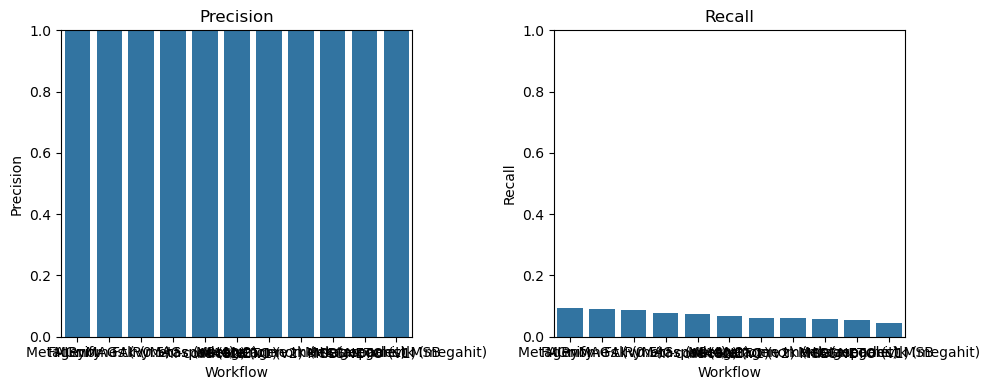

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# --- Precision plot ---
sns.barplot(
    data=metrics_df,
    x="source",
    y="precision",
    ax=axes[0]
)
axes[0].set_title("Precision")
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Precision")
axes[0].set_xlabel("Workflow")

# --- Recall plot ---
sns.barplot(
    data=metrics_df,
    x="source",
    y="recall",
    ax=axes[1]
)
axes[1].set_title("Recall")
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Recall")
axes[1].set_xlabel("Workflow")

plt.tight_layout()
plt.show()

# Version 2 (+nf-core mags and fairymags 0.5)